# 01 · Modelo núcleo: escalera M0 → M1 → M2

Especificación prerregistrada el 13-oct-2026 (ver `src/config.py`). **Solo datos hasta 2023-12-31.** El modelo se congeló el 6-nov-2026 (commit `74e9896`, etiqueta `v0.9-congelado`); el tramo de prueba 2024–2026 se evaluó una sola vez con `prueba.py` (resultados en `reports/prueba/`).

- M0: solo constante (benchmark ingenuo)
- M1: + NY y r_CLP
- M2: + carry, riesgo (EM-VXY) y carry × riesgo

Cada modelo se estima con ventana expansiva (desde 2004) y móvil (1.250 jornadas); el final es el promedio, calibrado con Platt anual sobre predicciones fuera de muestra.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src import config as C, datos, modelo, evaluacion as ev, figuras
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)

## 0. Versión

**Última actualización del notebook: 2026-11-12 11:10 (hora de Chile).** La celda siguiente muestra la fecha de modificación de cada archivo en tu PC y su sello de versión, para verificar que tienes la última versión (compárala con `CHANGELOG.md`).

In [2]:
import datetime as _dt
raiz = pathlib.Path.cwd().parent
filas = []
for f in sorted((raiz / 'src').glob('*.py')) + [raiz / 'CHANGELOG.md']:
    sello = next((l.split(':', 1)[1].strip() for l in f.read_text(encoding='utf-8').splitlines() if l.startswith('# Última actualización')), '—')
    filas.append({'archivo': f.relative_to(raiz).as_posix(),
                  'modificado en tu PC': _dt.datetime.fromtimestamp(f.stat().st_mtime).strftime('%Y-%m-%d %H:%M'),
                  'sello de versión': sello})
pd.DataFrame(filas).set_index('archivo')

,modificado en tu PC,sello de versión
archivo,,
src/__init__.py,2026-11-12 11:03,—
src/auditoria.py,2026-11-12 11:03,2026-11-06 17:46 (hora de Chile) — por defecto...
src/config.py,2026-11-12 11:03,2026-11-06 17:52 (hora de Chile) — congelamien...
src/datos.py,2026-11-12 11:03,2026-11-06 17:46 (hora de Chile) — cargar_base...
src/evaluacion.py,2026-11-12 11:03,2026-10-21 21:54 (hora de Chile) — E13: perfil...
src/figuras.py,2026-11-12 11:03,2026-10-21 21:54 (hora de Chile) — Figura 3: t...
src/modelo.py,2026-11-12 11:03,2026-10-21 21:54 (hora de Chile) — comentario ...
src/tablero.py,2026-11-12 11:03,2026-11-06 17:46 (hora de Chile) — muestra arc...
CHANGELOG.md,2026-11-12 11:05,—


In [3]:
print('Base leída:', C.ARCHIVO_BASE.name, '· huella', datos.huella_archivo(),
      '· modificada en tu PC', _dt.datetime.fromtimestamp(C.ARCHIVO_BASE.stat().st_mtime).strftime('%Y-%m-%d %H:%M'))
print('Huella de los datos que usa el modelo hasta 2023-12-29 (base del 6-oct y del 6-nov: d6ae3102ed):',
      datos.huella_datos(datos.cargar_base(), '2023-12-29'))

Base leída: base_usdclp_actualizada.xlsx · huella a198a23573 · modificada en tu PC 2026-11-12 11:03


Huella de los datos que usa el modelo hasta 2023-12-29 (base del 6-oct y del 6-nov: d6ae3102ed): d6ae3102ed


## 1. Tabla de modelamiento y prueba anti look-ahead

In [4]:
x = datos.cargar_base()
tabla_completa = datos.construir_tabla(x)
print('Diferencia máxima al truncar la base (debe ser 0):', datos.chequear_sin_lookahead(x, tabla_completa))
T = datos.recortar(tabla_completa)   # hasta 2023-12-31
T[['ny', 'r_clp', 'carry', 'riesgo', 'y', 'rex_sig']].describe().round(3).T

Diferencia máxima al truncar la base (debe ser 0): 0.0


,count,mean,std,min,25%,50%,75%,max
ny,4872.0,0.010,0.750,-4.685,-0.430,-0.034,0.420,5.344
r_clp,4872.0,0.011,1.043,-7.605,-0.581,-0.006,0.593,7.319
carry,4933.0,2.397,2.293,-1.730,0.337,1.599,4.170,8.429
riesgo,4933.0,10.169,3.057,5.800,8.530,9.600,11.050,32.960
y,4917.0,0.488,0.500,0.000,0.000,0.000,1.000,1.000
rex_sig,4917.0,-0.000,0.007,-0.074,-0.004,-0.000,0.004,0.046


## 2. Coeficientes en entrenamiento 2004–2019 (errores Newey-West, 5 rezagos)

Signos esperados: β(ny) > 0, β(r_clp) ≤ 0, β(carry) < 0, β(carry×riesgo) > 0.

In [5]:
tr = modelo._filas_validas(T[:'2019'], C.MODELOS['M2'])
for m in ['M1', 'M2']:
    r, _, _ = modelo.ajustar(tr, C.MODELOS[m], cov='HAC')
    print(m); display(pd.DataFrame({'coef': r.params, 't (NW)': r.tvalues, 'p': r.pvalues}).round(3).T)

M1


,const,ny,r_clp
coef,-0.053,0.173,-0.024
t (NW),-1.590,4.621,-0.640
p,0.112,0.000,0.522


M2


,const,ny,r_clp,carry,riesgo,carry_x_riesgo
coef,-0.055,0.174,-0.024,0.013,-0.058,0.005
t (NW),-1.610,4.648,-0.632,0.370,-1.270,0.210
p,0.107,0.000,0.528,0.711,0.204,0.834


## 3. Walk-forward 2010–2023: calidad de pronóstico

In [6]:
res, platt = modelo.correr_escalera(T, range(C.INICIO_OOS, C.VALIDACION[1] + 1))
cols = [f'{m}_{v}' for m in ['M0', 'M1', 'M2'] for v in ['exp', 'mov', 'prom', 'cal']]
for a, b in [('2010', '2019'), ('2020', '2023')]:
    print(f'--- {a}–{b}'); display(ev.tabla_pronostico(res, cols, a, b).round(4))

--- 2010–2019


,Brier,Log-loss,Acierto,p media,p desv.
M0_exp,0.2501,0.6934,0.5070,0.4802,0.0041
M0_mov,0.2501,0.6933,0.5070,0.4843,0.0110
M0_prom,0.2501,0.6933,0.5070,0.4822,0.0073
M0_cal,0.2501,0.6933,0.5070,0.4822,0.0073
M1_exp,0.2488,0.6908,0.5332,0.4784,0.0439
M1_mov,0.2489,0.6910,0.5307,0.4847,0.0469
M1_prom,0.2488,0.6908,0.5316,0.4816,0.0448
M1_cal,0.2503,0.6944,0.5303,0.4768,0.0640
M2_exp,0.2493,0.6917,0.5201,0.4831,0.0449
M2_mov,0.2520,0.6973,0.5167,0.4973,0.0614


--- 2020–2023


,Brier,Log-loss,Acierto,p media,p desv.
M0_exp,0.2499,0.6929,0.5109,0.4882,0.0001
M0_mov,0.2500,0.6932,0.4941,0.5010,0.0040
M0_prom,0.2499,0.6930,0.5109,0.4946,0.0020
M0_cal,0.2499,0.6930,0.5109,0.4946,0.0020
M1_exp,0.2491,0.6913,0.5327,0.4870,0.0402
M1_mov,0.2492,0.6916,0.5366,0.5011,0.0286
M1_prom,0.2490,0.6912,0.5287,0.4940,0.0340
M1_cal,0.2492,0.6915,0.5386,0.5007,0.0267
M2_exp,0.2487,0.6905,0.5337,0.4898,0.0411
M2_mov,0.2661,0.7322,0.5069,0.5660,0.1060


## 4. Tests en validación 2020–2023

Clark-West (una cola, H1: el modelo grande es mejor) y Diebold-Mariano con corrección HLN, ambos sobre Brier.

In [7]:
v = res['2020':'2023'].dropna(subset=['y'])
filas = []
for chico, grande in [('M0_cal','M1_cal'), ('M1_cal','M2_cal'), ('M0_cal','M2_cal'),
                      ('M0_exp','M2_exp'), ('M0_mov','M2_mov')]:
    cw_t, cw_p = ev.clark_west(v.y, v[chico], v[grande])
    dm_t, dm_p = ev.diebold_mariano(v.y, v[chico], v[grande])
    filas.append({'comparación': f'{grande} vs {chico}', 'CW t': cw_t, 'CW p': cw_p, 'DM t': dm_t, 'DM p': dm_p})
pd.DataFrame(filas).set_index('comparación').round(3)

,CW t,CW p,DM t,DM p
comparación,,,,
M1_cal vs M0_cal,1.903,0.029,0.930,0.176
M2_cal vs M1_cal,-0.457,0.676,-1.342,0.910
M2_cal vs M0_cal,0.554,0.290,-0.379,0.648
M2_exp vs M0_exp,2.418,0.008,0.999,0.159
M2_mov vs M0_mov,-0.167,0.566,-3.451,1.000


**Acierto direccional (DA) con test de Pesaran-Timmermann (1992)** — agregado el 20-oct. H0: el pronóstico de signo es independiente del resultado; descuenta el acierto que se obtendría por las frecuencias marginales.

In [8]:
filas = []
for a, b in [('2010', '2019'), ('2020', '2023')]:
    vv = res[a:b].dropna(subset=['y'])
    for m in ['M1_cal', 'M2_cal']:
        da, da0, z, pv = ev.pesaran_timmermann(vv.y, vv[m])
        filas.append({'tramo': f'{a}–{b}', 'modelo': m, 'DA': da, 'DA bajo independencia': da0,
                      'Siempre lo más frecuente': max(vv.y.mean(), 1 - vv.y.mean()), 'PT': z, 'p-valor': pv})
pd.DataFrame(filas).set_index(['tramo', 'modelo']).round(3)

DA  DA bajo independencia  Siempre lo más frecuente     PT  p-valor
tramo     modelo                                                                        
2010–2019 M1_cal  0.530                  0.503                     0.507  2.908    0.002
          M2_cal  0.512                  0.503                     0.507  0.975    0.165
2020–2023 M1_cal  0.539                  0.500                     0.511  2.437    0.007
          M2_cal  0.534                  0.501                     0.511  2.111    0.017

## 5. Calibración: parámetros de Platt por año (pendiente < 1 = el modelo bruto es sobreconfiado)

In [9]:
pd.DataFrame({m: {a: p[1] for a, p in platt[m].items()} for m in ['M1', 'M2']}).round(3)

,M1,M2
2011,2.404,1.894
2012,1.150,0.951
2013,1.110,0.945
2014,0.926,0.744
2015,0.837,0.718
2016,0.847,0.753
2017,0.796,0.730
2018,0.754,0.495
2019,0.779,0.463
2020,0.808,0.462


## 6. Valor económico en validación 2020–2023

**Regla oficial (13-oct):** Kelly fraccional discreto por utilidad, k = argmax U(k) = k·μ − k²σ²/(2c) − costo·|k − k_anterior|, k ∈ {−3,−1,0,1,3}. Se compara con la regla prerregistrada original (`posicion_kelly`), que tenía un defecto (ver registro E04). **Costo supuesto: 2 pb por unidad de cambio** hasta que el laboratorio lo informe.

In [10]:
tt = T.reindex(v.index); rex = v.rex.fillna(0); filas = {}; curvas = {}
for nombre in ['M1_cal', 'M2_cal']:
    for c in [C.KELLY_C, C.KELLY_C_ROBUSTEZ]:
        bt = ev.backtest(ev.posicion_kelly_utilidad(v[nombre], tt.abs_r_60, tt.sd_r_60, c=c), rex)
        filas[f'{nombre} utilidad c={c}'] = ev.resumen(bt, v.rex); curvas[f'{nombre} utilidad c={c}'] = bt
bt = ev.backtest(ev.posicion_kelly(v['M1_cal'], tt.abs_r_60, tt.sd_r_60, c=C.KELLY_C), rex)
filas['M1_cal regla original c=0.25'] = ev.resumen(bt, v.rex); curvas['M1_cal regla original c=0.25'] = bt
for ref, k in [('Comprar siempre (+1)', 1), ('Comprar siempre (+3)', 3), ('No operar (0)', 0)]:
    bt = ev.backtest(pd.Series(float(k), index=v.index), rex)
    filas[ref] = ev.resumen(bt, v.rex); curvas[ref] = bt
pd.DataFrame(filas).T.round(2)

,Ret. anual neto %,Ret. anual bruto %,Vol. anual %,Sharpe,Máx. drawdown %,% días en 0,% días en ±1,% días en ±3,Acierto días activos,Acierto días ±3 (DA@3x),Costos / PnL bruto %
M1_cal utilidad c=0.25,12.08,14.34,13.08,0.92,-9.98,54.26,42.48,3.27,0.55,0.52,15.73
M1_cal utilidad c=0.2,9.68,11.60,10.96,0.88,-8.24,62.67,35.25,2.08,0.55,0.52,16.53
M2_cal utilidad c=0.25,5.66,6.29,21.37,0.26,-44.17,62.28,30.99,6.73,0.52,0.53,10.00
M2_cal utilidad c=0.2,4.31,4.85,15.38,0.28,-22.59,70.20,26.63,3.17,0.53,0.50,11.12
M1_cal regla original c=0.25,17.18,20.77,25.47,0.67,-33.41,4.36,70.69,24.95,0.51,0.54,17.27
Comprar siempre (+1),0.38,0.39,15.60,0.02,-35.17,0.00,100.00,0.00,0.49,NaN,1.29
Comprar siempre (+3),1.15,1.16,46.79,0.02,-105.52,0.00,0.00,100.00,0.49,0.49,1.29
No operar (0),0.00,0.00,0.00,NaN,0.00,100.00,0.00,0.00,NaN,NaN,NaN


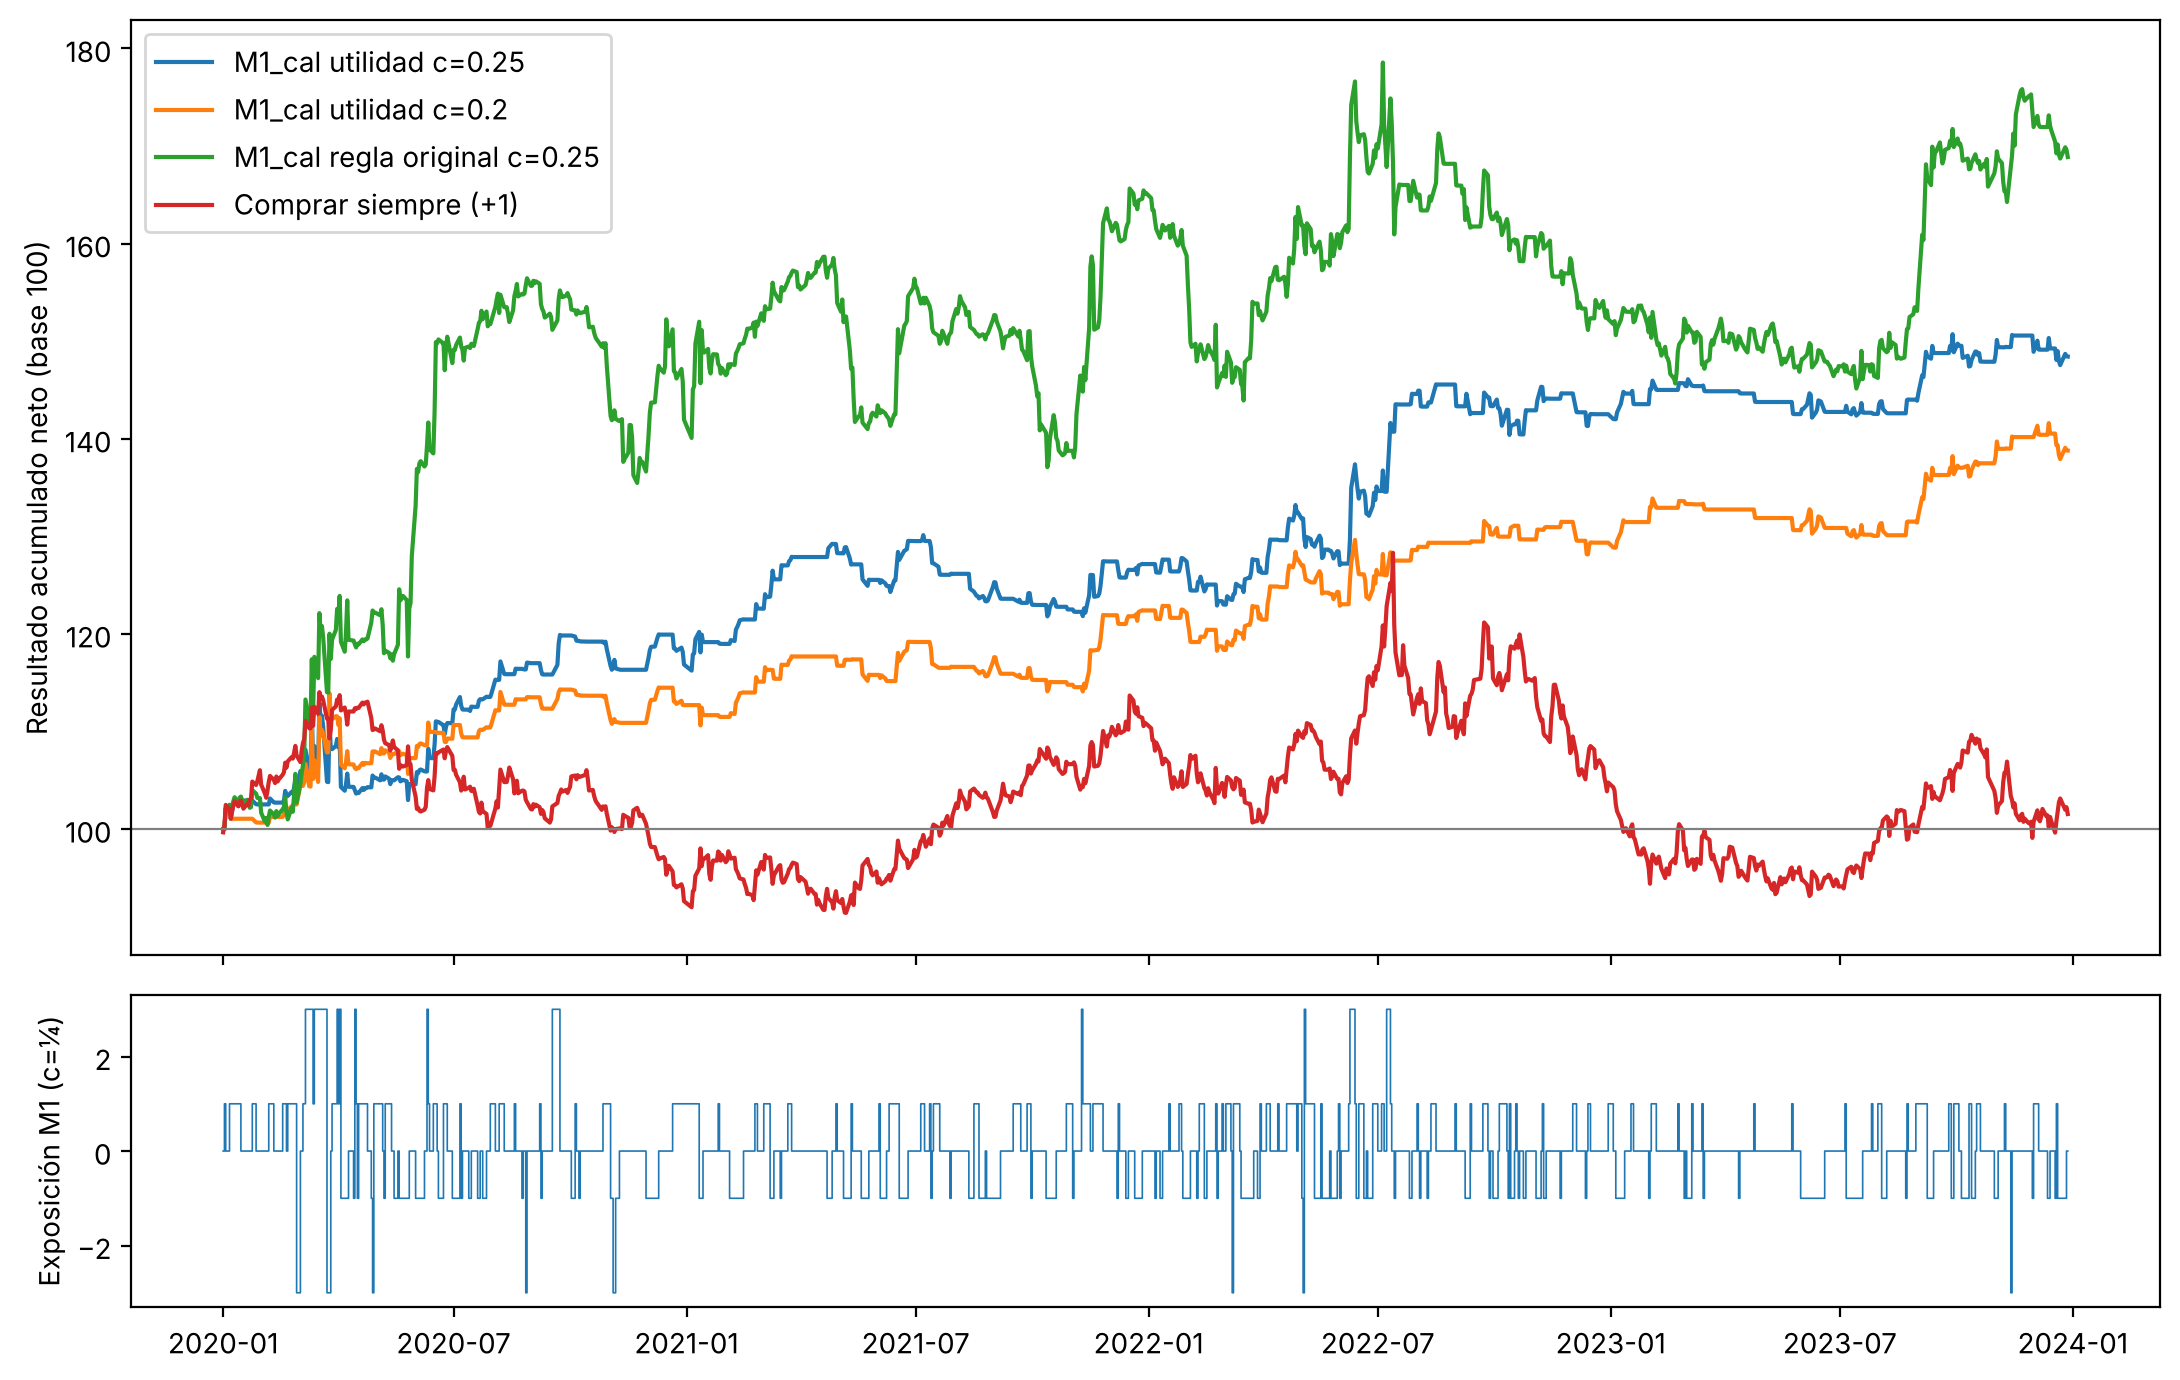

In [11]:
fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 7), sharex=True, gridspec_kw={'height_ratios': [3, 1]})
for k in ['M1_cal utilidad c=0.25', 'M1_cal utilidad c=0.2', 'M1_cal regla original c=0.25', 'Comprar siempre (+1)']:
    a1.plot(100 * (1 + curvas[k].neto.cumsum()), label=k)
a1.axhline(100, color='grey', lw=.8); a1.set_ylabel('Resultado acumulado neto (base 100)'); a1.legend()
a2.step(curvas['M1_cal utilidad c=0.25'].index, curvas['M1_cal utilidad c=0.25'].pos, lw=.6)
a2.set_ylabel('Exposición M1 (c=¼)'); plt.tight_layout(); plt.show()

### 6b. Estadísticas de trading de la estrategia oficial (agregado el 12-nov a pedido del laboratorio)

Resumen del backtest en el formato que pidió el laboratorio: retorno neto de carry y costos, volatilidad, Sharpe, drawdown máximo, porcentaje de aciertos y **número de operaciones**. Una *operación* es una jornada en que la exposición cambia respecto de la anterior (abrir, cerrar, invertir o escalar la posición); las *unidades transadas* suman |Δk| y son la base del costo (2 pb por unidad). La columna de la prueba 2024–2026 se lee de `reports/prueba/` (corrida única del 6-nov), no se recalcula aquí.

**Mecanismo de ejecución.** La señal del día *t* se calcula con los cierres de *t* (los de Nueva York incluidos, bajo el supuesto de cierre común indicado por el laboratorio). La exposición k_t se liquida con el retorno en exceso entre el cierre local de *t* y el de *t+1* (convención del torneo, cierre a cierre); no se usa el dólar observado. La operación la gatilla un cambio de k_t respecto de k_{t−1}: k_t = argmax_k [k·μ_t − k²σ_t²/(2c) − κ|k − k_{t−1}|], con μ_t = (2p_t − 1)·E|r|₆₀, σ_t de 60 jornadas y κ = 2 pb. La sección 8 reporta la misma secuencia de posiciones ejecutada a la apertura de *t+1*.

In [12]:
def estadisticas_trading(bt, rex):
    pos = bt.pos; n = bt.neto; acum = n.cumsum()
    cambio = pos.diff().abs().fillna(pos.abs()); act = pos != 0
    aperturas = (act & (pos.shift(1, fill_value=0) == 0)).sum()
    anios = len(bt) / 252
    return {'Jornadas': len(bt), 'Retorno neto anual %': n.mean() * 252 * 100, 'Retorno bruto anual %': bt.bruto.mean() * 252 * 100,
            'Acumulado neto %': acum.iloc[-1] * 100, 'Volatilidad anual %': n.std() * np.sqrt(252) * 100,
            'Sharpe': n.mean() / n.std() * np.sqrt(252), 'Drawdown máximo %': (acum - acum.cummax()).min() * 100,
            'Acierto días activos %': (np.sign(pos[act]) == np.sign(rex[act])).mean() * 100,
            'Acierto días ±3 %': (np.sign(pos[pos.abs() == 3]) == np.sign(rex[pos.abs() == 3])).mean() * 100 if (pos.abs() == 3).any() else np.nan,
            'N operaciones (cambios de exposición)': int((cambio > 0).sum()), 'Operaciones por año': (cambio > 0).sum() / anios,
            'Unidades transadas': cambio.sum(), 'Unidades por año': cambio.sum() / anios,
            'Días con posición': int(act.sum()), 'Tiempo en el mercado %': act.mean() * 100,
            'Días comprado (+)': int((pos > 0).sum()), 'Días vendido (−)': int((pos < 0).sum()),
            'Duración media de una posición (días)': act.sum() / aperturas if aperturas else np.nan,
            'Costos acumulados %': bt.costo.sum() * 100}
bt_v = curvas['M1_cal utilidad c=0.25']
col = {'Validación 2020–2023': estadisticas_trading(bt_v, v.rex.reindex(bt_v.index))}
ruta_p = pathlib.Path.cwd().parent / 'reports' / 'prueba' / 'serie_diaria_estrategia.csv'
if ruta_p.exists():
    bt_p = pd.read_csv(ruta_p, index_col=0, parse_dates=True)
    rex_p = tabla_completa['rex_sig'].reindex(bt_p.index)
    col['Prueba 2024–2026 (corrida única, 6-nov)'] = estadisticas_trading(bt_p, rex_p)
pd.DataFrame(col).round(2)

,Validación 2020–2023,"Prueba 2024–2026 (corrida única, 6-nov)"
Jornadas,1010.00,716.00
Retorno neto anual %,12.08,-5.14
Retorno bruto anual %,14.34,-3.17
Acumulado neto %,48.42,-14.61
Volatilidad anual %,13.08,9.58
Sharpe,0.92,-0.54
Drawdown máximo %,-9.98,-21.39
Acierto días activos %,54.76,47.58
Acierto días ±3 %,51.52,53.85
N operaciones (cambios de exposición),337.00,207.00


## 7. Robustez del modelo operativo (M1 calibrado, regla de utilidad, c = ¼)

In [13]:
v2 = res['2011':'2023'].dropna(subset=['y']); t2 = T.reindex(v2.index); rex2 = v2.rex.fillna(0)
pos = ev.posicion_kelly_utilidad(v2.M1_cal, t2.abs_r_60, t2.sd_r_60, c=C.KELLY_C)
bt = ev.backtest(pos, rex2); n = bt.neto
sh = lambda s: s.mean() / s.std() * np.sqrt(252)
print('Por año (2011–2012 tienen huecos en la base: interpretar con cautela)')
display(pd.DataFrame({'Retorno neto %': n.groupby(n.index.year).sum() * 100,
                      'Sharpe': n.groupby(n.index.year).apply(sh),
                      '% días en 0': (bt.pos == 0).groupby(bt.index.year).mean() * 100}).round(2))
w = n['2020':'2023']; s = w.sort_values()
print(f'Sharpe 2020–2023: {sh(w):.2f} | sin 1er semestre 2020: {sh(n["2020-07":"2023"]):.2f} | '
      f'sin 10 mejores y 10 peores días: {sh(s.iloc[10:-10]):.2f}')
rng = np.random.default_rng(0); k = pos['2020':'2023'].abs(); r = rex2['2020':'2023']
plac = [sh(k * rng.choice([-1, 1], len(k)) * r) for _ in range(1000)]
print(f'Placebo de signo aleatorio (1.000 sorteos): p95 = {np.percentile(plac, 95):.2f}; p-valor = {np.mean(np.array(plac) >= sh(w)):.3f}')

Por año (2011–2012 tienen huecos en la base: interpretar con cautela)


,Retorno neto %,Sharpe,% días en 0
fecha,,,
2011,72.62,2.34,4.41
2012,45.83,3.26,10.08
2013,-6.68,-0.26,2.46
2014,-3.52,-0.17,8.73
2015,6.37,0.33,19.42
2016,19.32,1.24,37.25
2017,-5.45,-0.53,45.93
2018,5.74,0.50,33.47
2019,3.35,0.42,54.51


Sharpe 2020–2023: 0.92 | sin 1er semestre 2020: 1.00 | sin 10 mejores y 10 peores días: 1.02
Placebo de signo aleatorio (1.000 sorteos): p95 = 0.86; p-valor = 0.040


## 8. Ejecución realista vs. convención del torneo (E07, agregado el 20-oct)

Mismo modelo y mismas posiciones; solo cambia el precio de ejecución. La convención del torneo es cierre→cierre. En la práctica, al decidir al cierre de t el primer precio onshore transable es la apertura de t+1.

In [14]:
tramos = [('Torneo: cierre→cierre', 'rex_sig'), ('Realista: apertura→apertura', 'rex_ap_ap'),
          ('Solo sesión t+1: apertura→cierre', 'rex_ap_ci'), ('Solo tramo nocturno (no transable)', 'rex_noche')]
for a, b in [('2011', '2019'), ('2020', '2023')]:
    vv = res[a:b].dropna(subset=['y']); t3 = T.reindex(vv.index)
    pos = ev.posicion_kelly_utilidad(vv.M1_cal, t3.abs_r_60, t3.sd_r_60, c=C.KELLY_C)
    tabla_ej = pd.DataFrame({nom: ev.resumen(ev.backtest(pos, t3[col].fillna(0)), t3[col]) for nom, col in tramos}).T
    print(f'--- {a}–{b}'); display(tabla_ej[['Ret. anual neto %', 'Sharpe', 'Máx. drawdown %', 'Acierto días activos']].round(2))
    print('Descomposición que suma (costos cobrados una vez; % anual):')
    display(ev.descomposicion_tramos(pos, t3).round(2).to_frame(f'{a}–{b}').T)
    print(f'Correlación tramo nocturno – sesión: {t3.rex_noche.corr(t3.rex_ap_ci):.3f}')

--- 2011–2019


,Ret. anual neto %,Sharpe,Máx. drawdown %,Acierto días activos
Torneo: cierre→cierre,16.50,0.81,-33.99,0.50
Realista: apertura→apertura,-13.39,-0.64,-127.77,0.48
Solo sesión t+1: apertura→cierre,-12.74,-0.84,-121.44,0.46
Solo tramo nocturno (no transable),20.91,1.39,-42.92,0.54


Descomposición que suma (costos cobrados una vez; % anual):


,Tramo nocturno (bruto),Sesión (bruto),Retorno del tipo de cambio,Carry recibido,Costos,Resultado neto,Posición media
2011–2019,25.41,-8.24,17.18,3.83,-4.5,16.5,-0.95


Correlación tramo nocturno – sesión: -0.112
--- 2020–2023


,Ret. anual neto %,Sharpe,Máx. drawdown %,Acierto días activos
Torneo: cierre→cierre,12.08,0.92,-9.98,0.55
Realista: apertura→apertura,10.64,0.68,-16.48,0.54
Solo sesión t+1: apertura→cierre,2.52,0.24,-10.72,0.54
Solo tramo nocturno (no transable),7.25,0.76,-10.55,0.53


Descomposición que suma (costos cobrados una vez; % anual):


,Tramo nocturno (bruto),Sesión (bruto),Retorno del tipo de cambio,Carry recibido,Costos,Resultado neto,Posición media
2020–2023,9.5,4.78,14.28,0.06,-2.26,12.08,0.02


Correlación tramo nocturno – sesión: -0.097


**Lectura:** en 2011–2019 toda la ventaja está en el tramo nocturno no transable (asincronía de cierres), y ejecutar a la apertura da Sharpe negativo: durante la sesión el CLP revierte parte del salto de apertura. Se reporta como hallazgo en el informe.

**21-oct (auditoría):** (i) la ejecución apertura→apertura ahora paga el carry de t+1 a t+2 (antes, el de t a t+1, desfasado un día); (ii) las filas «solo sesión» y «solo nocturno» de la tabla de arriba cobran el costo cada una, así que no suman: la descomposición de abajo usa los tramos en bruto y cobra carry y costos una sola vez, y su resultado neto coincide con el cierre a cierre.

## 9. Sensibilidad a costos: ¿dónde deja de ser rentable? (E08, 20-oct)

Costo por unidad de cambio de exposición, en pb (≈ medio spread; a ~985 CLP/USD, **1 CLP ≈ 10 pb**; corregido el 20-oct 19:15, antes decía 1 pb). Referencias retail al 20-oct-2026: CFD (Admiral) ~2–4 pb + swap; Buda ~7–10 pb; apps/fintech (Global66, Racional, XTB) ~10–40 pb; Fintual ~47 pb; AFEX ~100 pb; bancos ~75–250 pb. **Fija** = posiciones decididas con 2 pb; **reoptimiza** = la regla decide con el costo nuevo.

In [15]:
grid = [0, 1, 2, 3, 4, 5, 6, 8, 10, 12, 15, 20, 25]
for a, b in [('2011', '2019'), ('2020', '2023')]:
    vv = res[a:b].dropna(subset=['y']); t4 = T.reindex(vv.index)
    S = ev.sensibilidad_costos(vv.M1_cal, t4.abs_r_60, t4.sd_r_60, vv.rex.fillna(0), grid)
    print(f'--- {a}–{b}'); display(S.pivot(index='costo_pb', columns='regla', values=['Ret. anual neto %', 'Sharpe']).round(2))

--- 2011–2019


Ret. anual neto %            Sharpe           
regla                 fija reoptimiza   fija reoptimiza
costo_pb                                               
0                    21.00      27.70   1.02       1.23
1                    18.75      22.60   0.92       1.06
2                    16.50      16.50   0.81       0.81
3                    14.25      16.96   0.70       0.84
4                    12.00       9.86   0.59       0.50
5                     9.75       8.40   0.48       0.44
6                     7.50       4.73   0.37       0.24
8                     2.99       7.11   0.15       0.45
10                   -1.51       2.05  -0.07       0.12
12                   -6.01       2.63  -0.29       0.13
15                  -12.77       4.27  -0.62       0.20
20                  -24.02       1.03  -1.16       0.04
25                  -35.28       2.30  -1.68       0.08

--- 2020–2023


Ret. anual neto %            Sharpe           
regla                 fija reoptimiza   fija reoptimiza
costo_pb                                               
0                    14.34      12.30   1.10       0.72
1                    13.21       8.91   1.01       0.60
2                    12.08      12.08   0.92       0.92
3                    10.95      11.10   0.84       0.93
4                     9.83       7.23   0.75       0.64
5                     8.70       4.57   0.66       0.44
6                     7.57       0.43   0.58       0.04
8                     5.31       3.00   0.41       0.22
10                    3.06       0.82   0.23       0.08
12                    0.80      -3.47   0.06      -0.67
15                   -2.58      -0.38  -0.20      -0.13
20                   -8.22       0.00  -0.62        NaN
25                  -13.86       0.00  -1.04        NaN

In [16]:
filas = []
for a, b in [('2011', '2019'), ('2020', '2023')]:
    vv = res[a:b].dropna(subset=['y']); t4 = T.reindex(vv.index)
    for c in [C.KELLY_C, C.KELLY_C_ROBUSTEZ]:
        pos = ev.posicion_kelly_utilidad(vv.M1_cal, t4.abs_r_60, t4.sd_r_60, c=c)
        for ej, col in [('cierre→cierre', 'rex_sig'), ('apertura→apertura', 'rex_ap_ap')]:
            filas.append({'tramo': f'{a}–{b}', 'c': c, 'ejecución': ej,
                          'costo de equilibrio (pb)': ev.costo_equilibrio(pos, t4[col].fillna(0))})
print('Costo por unidad de cambio que deja el retorno neto en 0 (negativo = ya pierde antes de costos)')
display(pd.DataFrame(filas).round(2))
vv = res['2020':'2023'].dropna(subset=['y']); t4 = T.reindex(vv.index)
cfd = {f'swap +{m}%/año': ev.sensibilidad_costos(vv.M1_cal, t4.abs_r_60, t4.sd_r_60, vv.rex.fillna(0), [4], swap_anual=m / 100)
       .query('regla == "fija"')[['Ret. anual neto %', 'Sharpe']].iloc[0] for m in [0, 2, 5, 13]}
print('CFD 2020–2023: costo 4 pb por unidad + sobreprecio del swap sobre el carry justo')
display(pd.DataFrame(cfd).T.round(2))

Costo por unidad de cambio que deja el retorno neto en 0 (negativo = ya pierde antes de costos)


,tramo,c,ejecución,costo de equilibrio (pb)
0,2011–2019,0.25,cierre→cierre,9.33
1,2011–2019,0.25,apertura→apertura,-3.95
2,2011–2019,0.20,cierre→cierre,10.86
3,2011–2019,0.20,apertura→apertura,-3.09
4,2020–2023,0.25,cierre→cierre,12.71
5,2020–2023,0.25,apertura→apertura,11.43
6,2020–2023,0.20,cierre→cierre,12.10
7,2020–2023,0.20,apertura→apertura,14.17


CFD 2020–2023: costo 4 pb por unidad + sobreprecio del swap sobre el carry justo


,Ret. anual neto %,Sharpe
swap +0%/año,9.83,0.75
swap +2%/año,8.78,0.67
swap +5%/año,7.21,0.55
swap +13%/año,3.03,0.23


**Lectura:** con la convención del torneo, el punto de equilibrio está en ~9–13 pb por unidad de cambio. Para un retail solo el CFD (2–4 pb) queda bajo el equilibrio (Sharpe 0,59–0,75 sin swap); Buda queda en el borde y sin venta corta; apps, casas de cambio y bancos hacen perder dinero. Reoptimizar con el costo no rescata la estrategia: deja de operar y el Sharpe cae a ~0,1–0,2. En 2011–2019 con ejecución a la apertura ya pierde antes de costos, así que no hay costo de equilibrio. El swap del CFD (~13–15 % anual cobrado a ambos lados) es el costo dominante: con 2–4 pb y 13 % de sobrecosto, 2020–2023 rinde 3,0–5,3 % (Sharpe 0,23–0,41) y 2011–2019 pierde.

## 10. Evaluación formal contra las referencias (E09, 20-oct)

Diseño acordado el 20-oct, **antes** de ver resultados:
- Se compara la ganancia neta diaria: d_t = PnL_modelo − PnL_ref (costo 2 pb, carry incluido).
- **Diebold-Mariano con pérdida económica** (−PnL), Newey-West 5 rezagos + HLN, una cola.
- **Bootstrap estacionario pareado** (Politis-Romano), 10.000 réplicas, bloque medio 10 días (robustez 5 y 20), p-valor centrado bajo H0.
- **Estadístico principal: diferencia de retorno neto anual**; Sharpe con igual prominencia.
- «Exposición fija 1» es ambigua en las bases: se evalúan ambas lecturas (+1/+3 siempre y señal M1 con tamaño fijo 1). Holm se aplica sobre las 4 comparaciones (más conservador que sobre 3).
- **Sharpe deflactado** con N = 48 variantes backtesteadas (M1/M2/M1C × 4 versiones × c ∈ {¼, ⅕} × 2 reglas; M1C sumado el 20-oct tras E10).

In [17]:
refs = lambda idx_, p_: {'No operar (0)': pd.Series(0., index=idx_), 'Comprar siempre (+1)': pd.Series(1., index=idx_),
                         'Comprar siempre (+3)': pd.Series(3., index=idx_), 'Señal M1, tamaño fijo 1': np.sign(p_ - .5)}
robustez = {}
for a, b in [('2011', '2019'), ('2020', '2023')]:
    vv = res[a:b].dropna(subset=['y']); t5 = T.reindex(vv.index); rx = vv.rex.fillna(0)
    nm = ev.backtest(ev.posicion_kelly_utilidad(vv.M1_cal, t5.abs_r_60, t5.sd_r_60), rx).neto
    for L in [10, 5, 20]:
        idx = ev.indices_bootstrap_estacionario(len(nm), bloque=L)
        R = pd.DataFrame({k: ev.comparar_con_referencia(nm, ev.backtest(p_, rx).neto, idx) for k, p_ in refs(vv.index, vv.M1_cal).items()}).T
        R['p Holm (retorno)'] = ev.holm(R['p bootstrap (retorno)'])
        if L == 10:
            print(f'--- {a}–{b} (bloque 10)'); display(R.round(3))
        robustez[(f'{a}–{b}', f'bloque {L}')] = R['p bootstrap (retorno)']
    sh = [ (lambda n_: n_.mean() / n_.std())(ev.backtest(f(vv[f'{m}_{ver}'], t5.abs_r_60, t5.sd_r_60, c=c), rx).neto)
           for m in ['M1', 'M2', 'M1C'] for ver in ['exp', 'mov', 'prom', 'cal'] for c in [0.25, 0.2]
           for f in [ev.posicion_kelly_utilidad, ev.posicion_kelly]]
    print(f'Sharpe {nm.mean() / nm.std() * np.sqrt(252):.2f} | lugar entre los {len(sh)} ensayos: '
          f'{int((np.array(sh) > nm.mean() / nm.std() + 1e-12).sum()) + 1}.º')
    for N_ in [len(sh), 100, 200]:   # A4: N mayores cubren cribado de series, ventanas y embargo
        dsr, sr0, N = ev.sharpe_deflactado(nm, sh, N=N_)
        print(f'   N = {N}: umbral SR0 = {sr0:.2f} | Sharpe deflactado (prob.) = {dsr:.3f}')
print('Robustez al largo de bloque: p bootstrap de la diferencia de retorno'); pd.DataFrame(robustez).round(3)

--- 2011–2019 (bloque 10)


,Dif. retorno anual %,IC 95% inf.,IC 95% sup.,p bootstrap (retorno),Dif. Sharpe,p bootstrap (Sharpe),DM (HLN),p DM,p Holm (retorno)
No operar (0),16.502,1.017,33.344,0.027,0.806,0.016,2.197,0.014,0.108
Comprar siempre (+1),14.938,-4.090,34.401,0.067,0.653,0.128,1.606,0.054,0.144
Comprar siempre (+3),11.811,-17.933,41.677,0.210,0.653,0.128,0.784,0.216,0.210
"Señal M1, tamaño fijo 1",10.116,-0.911,22.374,0.048,0.179,0.228,1.852,0.032,0.144


Sharpe 0.81 | lugar entre los 48 ensayos: 12.º
   N = 48: umbral SR0 = 0.45 | Sharpe deflactado (prob.) = 0.852
   N = 100: umbral SR0 = 0.51 | Sharpe deflactado (prob.) = 0.812
   N = 200: umbral SR0 = 0.55 | Sharpe deflactado (prob.) = 0.773


--- 2020–2023 (bloque 10)


,Dif. retorno anual %,IC 95% inf.,IC 95% sup.,p bootstrap (retorno),Dif. Sharpe,p bootstrap (Sharpe),DM (HLN),p DM,p Holm (retorno)
No operar (0),12.082,1.897,22.654,0.012,0.923,0.014,2.250,0.012,0.049
Comprar siempre (+1),11.698,-4.742,28.204,0.082,0.899,0.073,1.339,0.090,0.246
Comprar siempre (+3),10.932,-32.630,54.933,0.304,0.899,0.073,0.475,0.317,0.608
"Señal M1, tamaño fijo 1",3.171,-12.297,19.559,0.330,0.352,0.264,0.421,0.337,0.608


Sharpe 0.92 | lugar entre los 48 ensayos: 7.º
   N = 48: umbral SR0 = 0.74 | Sharpe deflactado (prob.) = 0.645
   N = 100: umbral SR0 = 0.83 | Sharpe deflactado (prob.) = 0.575
   N = 200: umbral SR0 = 0.91 | Sharpe deflactado (prob.) = 0.511
Robustez al largo de bloque: p bootstrap de la diferencia de retorno


2011–2019                    2020–2023                   
                        bloque 10 bloque 5 bloque 20 bloque 10 bloque 5 bloque 20
No operar (0)               0.027    0.019     0.046     0.012    0.018     0.012
Comprar siempre (+1)        0.067    0.055     0.084     0.082    0.091     0.077
Comprar siempre (+3)        0.210    0.214     0.222     0.304    0.319     0.306
Señal M1, tamaño fijo 1     0.048    0.038     0.071     0.330    0.329     0.334

**Lectura (validación, no es el resultado oficial):** la estrategia le gana con significancia a *no operar* en ambos tramos (tras Holm solo en 2020–2023). Contra *comprar siempre (+1)* la diferencia es grande (~12–15 pp al año) pero marginal (p ≈ 0,07–0,09); contra *+3* no es significativa por la volatilidad de esa referencia. La regla de tamaño agrega valor frente a la señal con tamaño fijo en 2011–2019 (p ≈ 0,05), no en 2020–2023. Sharpe deflactado < 0,95 en ambos tramos (ver valores arriba; bajan al sumar los ensayos de M1C). **Problema de potencia:** con Sharpe 0,9 y ~690 días de prueba, t ≈ 0,9·√2,7 ≈ 1,5; aunque la ventaja sea real, es esperable no alcanzar p < 0,05 en el tramo de prueba.

## 11. Candidato prerregistrado: M1 + cobre COMEX (E10, 20-oct)

Prerregistrado a las 17:52 del 20-oct, antes de correrlo (`src/config.py`, registro E10). COMEX liquida a las 13:00 ET, después del cierre onshore del CLP (~13:00–13:30), igual que la señal NY. Días de cambio de contrato: si |r_HG − r_LME| > 3 desv. se usa r_LME. **Regla: entra solo si Clark-West vs M1 da p < 0,05 en 2020–2023.**

In [18]:
print('Días con cambio de contrato reemplazados por LME (2004–2023):', int(T.cobre_roll.sum()))
tr = modelo._filas_validas(T[:'2019'], C.MODELOS['M1C']); r, _, _ = modelo.ajustar(tr, C.MODELOS['M1C'], cov='HAC')
display(pd.DataFrame({'coef': r.params, 't (NW)': r.tvalues, 'p': r.pvalues}).round(3).T)
display(T[['ny', 'r_clp', 'cobre']].corr().round(2))
filas = []
for a, b in [('2010', '2019'), ('2020', '2023')]:
    vv = res[a:b].dropna(subset=['y']); t6 = T.reindex(vv.index)
    cw_t, cw_p = ev.clark_west(vv.y, vv.M1_cal, vv.M1C_cal)
    ve = vv['2011':] if a == '2010' else vv; te = T.reindex(ve.index)   # valor económico desde 2011 (2010 sin Platt), como en las secciones 7–10
    pos = ev.posicion_kelly_utilidad(ve.M1C_cal, te.abs_r_60, te.sd_r_60)
    rs = ev.resumen(ev.backtest(pos, ve.rex.fillna(0)), ve.rex)
    filas.append({'tramo': f'{a}–{b}', 'Brier M1': ev.brier(vv.M1_cal, vv.y), 'Brier M1C': ev.brier(vv.M1C_cal, vv.y),
                  'CW t': cw_t, 'CW p': cw_p, 'Ret. neto M1C %': rs['Ret. anual neto %'], 'Sharpe M1C': rs['Sharpe']})
pd.DataFrame(filas).set_index('tramo').round(4)

Días con cambio de contrato reemplazados por LME (2004–2023): 90


,const,ny,r_clp,cobre
coef,-0.053,0.176,-0.019,0.017
t (NW),-1.590,4.565,-0.494,0.471
p,0.112,0.000,0.622,0.638


,ny,r_clp,cobre
ny,1.00,0.48,-0.38
r_clp,0.48,1.00,-0.39
cobre,-0.38,-0.39,1.00


,Brier M1,Brier M1C,CW t,CW p,Ret. neto M1C %,Sharpe M1C
tramo,,,,,,
2010–2019,0.2503,0.2501,1.448,0.0738,15.5837,0.7861
2020–2023,0.2492,0.2492,-0.129,0.5513,8.9605,0.7765


**Resultado: M1C se descarta.** En 2004–2019 el coeficiente del cobre no es significativo (t ≈ 0,5) una vez que está la señal NY (correlación −0,38): el movimiento del cobre después del cierre ya está contenido en las monedas emergentes y el dólar global. Clark-West en validación: p = 0,55 (en 2010–2019, p = 0,07). El valor económico también es menor (Sharpe 0,78 vs 0,92 en 2020–2023). **M1 sigue siendo el modelo operativo.**

## 12. Perfiles de inversionista (E12, 21-oct)

Costo en pesos por dólar comprado o vendido, según la experiencia profesional de uno de los autores en carteras discrecionales de alto patrimonio: **institucional 0,5 CLP**, **retail 2 CLP**. El costo diario en fracción es pesos / tipo de cambio del día (por eso es mayor en pb cuando el dólar estaba más barato). Cada perfil usa la regla de Kelly con su propio costo ('regla propia'); como comparación, se cobran esos costos a las posiciones decididas con 2 pb. Prerregistrado para la corrida única del tramo de prueba (hecha el 6-nov).

In [19]:
cols_p = ['Ret. anual neto %', 'Vol. anual %', 'Sharpe', 'Máx. drawdown %', '% días en 0', 'Costos / PnL bruto %', 'Costo medio (pb)']
for a, b in [('2011', '2019'), ('2020', '2023')]:
    vv = res[a:b].dropna(subset=['y']); t7 = T.reindex(vv.index)
    P = ev.perfiles_inversionista(vv.M1_cal, t7.abs_r_60, t7.sd_r_60, vv.rex.fillna(0), t7.spot)
    print(f'--- {a}–{b} (tipo de cambio medio {t7.spot.mean():.0f})'); display(P[cols_p].round(2))

--- 2011–2019 (tipo de cambio medio 603)


,Ret. anual neto %,Vol. anual %,Sharpe,Máx. drawdown %,% días en 0,Costos / PnL bruto %,Costo medio (pb)
Torneo (2 pb),16.50,20.46,0.81,-33.99,25.18,21.44,NaN
"Institucional (0.5 CLP), regla propia",7.04,15.66,0.45,-32.71,33.13,39.55,8.46
"Institucional (0.5 CLP), posiciones del torneo",1.00,20.47,0.05,-70.21,25.18,95.24,NaN
"Retail (2.0 CLP), regla propia",-0.65,2.21,-0.29,-5.43,99.38,306.83,33.86
"Retail (2.0 CLP), posiciones del torneo",-59.02,21.96,-2.69,-478.90,25.18,380.97,NaN


--- 2020–2023 (tipo de cambio medio 816)


,Ret. anual neto %,Vol. anual %,Sharpe,Máx. drawdown %,% días en 0,Costos / PnL bruto %,Costo medio (pb)
Torneo (2 pb),12.08,13.08,0.92,-9.98,54.26,15.73,NaN
"Institucional (0.5 CLP), regla propia",2.00,11.66,0.17,-16.77,51.68,39.67,6.16
"Institucional (0.5 CLP), posiciones del torneo",7.51,13.09,0.57,-11.86,54.26,47.61,NaN
"Retail (2.0 CLP), regla propia",0.00,0.00,NaN,0.00,100.00,NaN,24.65
"Retail (2.0 CLP), posiciones del torneo",-12.97,13.33,-0.97,-60.03,54.26,190.45,NaN


**Lectura:** el inversionista institucional gana dinero, pero mucho menos que con la convención del torneo; el retail, sabiendo su costo, prácticamente no opera (y si operara con las posiciones del torneo perdería). Con costos altos, la regla que conoce su costo rinde menos que mantener las posiciones de 2 pb en 2020–2023: al operar menos pierde días buenos, porque la ventaja es de alta frecuencia. Parte de esa diferencia viene de una limitación declarada de la regla: cobra el costo completo de un cambio contra la ganancia de un solo día (auditoría A5).

### 12b. E13: perfiles × ejecución (prerregistrado el 21-oct para la corrida única del tramo de prueba)

Cambio de **reporte**, no de modelo: las mismas posiciones de E12 se liquidan con la convención del torneo (cierre a cierre) y con la ejecución disponible para quien decide después del cierre de Nueva York (apertura a apertura). En el tramo de prueba se reportará esta misma tabla, tal como salga (`ev.perfiles_por_ejecucion`, `C.EJECUCIONES_E13`).

In [20]:
for a, b in [('2011', '2019'), ('2020', '2023')]:
    vv = res[a:b].dropna(subset=['y']); t8 = T.reindex(vv.index)
    E = ev.perfiles_por_ejecucion(vv.M1_cal, t8.abs_r_60, t8.sd_r_60, t8)
    print(f'--- {a}–{b}'); display(E[['Ret. anual neto %', 'Sharpe', 'Máx. drawdown %', '% días en 0']].round(2))

--- 2011–2019


Ret. anual neto %  Sharpe  Máx. drawdown %  % días en 0
ejecución                perfil                                                                                                 
cierre a cierre (torneo) Torneo (2 pb)                                               16.50    0.81           -33.99        25.18
                         Institucional (0.5 CLP), regla propia                        7.04    0.45           -32.71        33.13
                         Institucional (0.5 CLP), posiciones del torneo               1.00    0.05           -70.21        25.18
                         Retail (2.0 CLP), regla propia                              -0.65   -0.29            -5.43        99.38
                         Retail (2.0 CLP), posiciones del torneo                    -59.02   -2.69          -478.90        25.18
apertura a apertura      Torneo (2 pb)                                              -13.39   -0.64          -127.77        25.18
                         Institucional (0.5 CLP), regla propia                       -5.36   -0.31           -70.12        33.13
                         Institucional (0.5 CLP), posiciones del torneo             -28.89   -1.37          -245.66        25.18
                         Retail (2.0 CLP), regla propia                              -1.94   -0.60           -16.71        99.38
                         Retail (2.0 CLP), posiciones del torneo                    -88.91   -3.85          -734.30        25.18

--- 2020–2023


Ret. anual neto %  Sharpe  Máx. drawdown %  % días en 0
ejecución                perfil                                                                                                 
cierre a cierre (torneo) Torneo (2 pb)                                               12.08    0.92            -9.98        54.26
                         Institucional (0.5 CLP), regla propia                        2.00    0.17           -16.77        51.68
                         Institucional (0.5 CLP), posiciones del torneo               7.51    0.57           -11.86        54.26
                         Retail (2.0 CLP), regla propia                               0.00     NaN             0.00       100.00
                         Retail (2.0 CLP), posiciones del torneo                    -12.97   -0.97           -60.03        54.26
apertura a apertura      Torneo (2 pb)                                               10.64    0.68           -16.48        54.26
                         Institucional (0.5 CLP), regla propia                        0.88    0.06           -19.27        51.68
                         Institucional (0.5 CLP), posiciones del torneo               6.07    0.39           -18.33        54.26
                         Retail (2.0 CLP), regla propia                               0.00     NaN             0.00       100.00
                         Retail (2.0 CLP), posiciones del torneo                    -14.41   -0.91           -71.10        54.26

## 13. Tablas del informe no cubiertas arriba (21-oct)

Para que cada tabla del informe salga de este notebook: estadísticas descriptivas (Tabla 3), valor económico 2011–2019 (panel B de la Tabla 7) y resultado anual con la referencia de comprar siempre (Tabla 9).

In [21]:
d = T[:'2023']
desc = pd.DataFrame({'Retorno USD/CLP (pb)': d.r_sig * 1e4, 'Carry del período (pb)': d.carry_periodo * 1e4,
                     'Retorno en exceso (pb)': d.rex_sig * 1e4, 'Señal NY': d.ny, 'r_CLP': d.r_clp,
                     'Diferencial de tasas (%)': d.carry, 'Volatilidad emergente': d.riesgo}).describe().T
display(desc[['count', 'mean', 'std', 'min', 'max']].round(2))
print(f'Días con alza en exceso de carry: {d.y.mean():.1%}')

,count,mean,std,min,max
Retorno USD/CLP (pb),4932.0,0.80,74.73,-736.94,467.92
Carry del período (pb),4933.0,1.02,1.48,-1.26,33.62
Retorno en exceso (pb),4917.0,-0.38,74.14,-739.00,456.99
Señal NY,4872.0,0.01,0.75,-4.69,5.34
r_CLP,4872.0,0.01,1.04,-7.60,7.32
Diferencial de tasas (%),4933.0,2.40,2.29,-1.73,8.43
Volatilidad emergente,4933.0,10.17,3.06,5.80,32.96


Días con alza en exceso de carry: 48.8%


In [22]:
vB = res['2011':'2019'].dropna(subset=['y']); tB = T.reindex(vB.index); rB = vB.rex.fillna(0); fB = {}
for c in [C.KELLY_C, C.KELLY_C_ROBUSTEZ]:
    fB[f'M1 c={c}'] = ev.resumen(ev.backtest(ev.posicion_kelly_utilidad(vB.M1_cal, tB.abs_r_60, tB.sd_r_60, c=c), rB), vB.rex)
fB['Señal tamaño fijo'] = ev.resumen(ev.backtest(np.sign(vB.M1_cal - .5), rB), vB.rex)
for ref, k in [('Comprar siempre (+1)', 1), ('Comprar siempre (+3)', 3), ('No operar (0)', 0)]:
    fB[ref] = ev.resumen(ev.backtest(pd.Series(float(k), index=vB.index), rB), vB.rex)
print('Panel B, 2011–2019'); pd.DataFrame(fB).T.round(2)

Panel B, 2011–2019


,Ret. anual neto %,Ret. anual bruto %,Vol. anual %,Sharpe,Máx. drawdown %,% días en 0,% días en ±1,% días en ±3,Acierto días activos,Acierto días ±3 (DA@3x),Costos / PnL bruto %
M1 c=0.25,16.50,21.00,20.46,0.81,-33.99,25.18,38.36,36.46,0.50,0.52,21.44
M1 c=0.2,18.42,22.58,19.48,0.95,-31.37,29.65,39.03,31.32,0.51,0.53,18.41
Señal tamaño fijo,6.39,10.65,10.18,0.63,-23.71,0.00,100.00,0.00,0.52,NaN,40.03
Comprar siempre (+1),1.56,1.57,10.20,0.15,-26.95,0.00,100.00,0.00,0.50,NaN,0.15
Comprar siempre (+3),4.69,4.70,30.60,0.15,-80.86,0.00,0.00,100.00,0.50,0.50,0.15
No operar (0),0.00,0.00,0.00,NaN,0.00,100.00,0.00,0.00,NaN,NaN,NaN


In [23]:
v3 = res['2011':'2023'].dropna(subset=['y']); t3_ = T.reindex(v3.index); r3 = v3.rex.fillna(0)
b3 = ev.backtest(ev.posicion_kelly_utilidad(v3.M1_cal, t3_.abs_r_60, t3_.sd_r_60), r3); n3 = b3.neto
bh = ev.backtest(pd.Series(1., index=v3.index), r3).neto; yr = n3.index.year
sharpe = lambda x: x.mean() / x.std() * np.sqrt(252)   # 'sh' se reutiliza en la sección 10
pd.DataFrame({'Retorno neto %': n3.groupby(yr).sum() * 100, 'Sharpe': n3.groupby(yr).apply(sharpe),
              '% en 0': (b3.pos == 0).groupby(yr).mean() * 100, '% en ±3': (b3.pos.abs() == 3).groupby(yr).mean() * 100,
              'Comprar siempre %': bh.groupby(yr).sum() * 100}).round(2)

,Retorno neto %,Sharpe,% en 0,% en ±3,Comprar siempre %
fecha,,,,,
2011,72.62,2.34,4.41,80.18,4.15
2012,45.83,3.26,10.08,68.22,-16.55
2013,-6.68,-0.26,2.46,91.39,6.16
2014,-3.52,-0.17,8.73,44.84,9.84
2015,6.37,0.33,19.42,34.30,10.54
2016,19.32,1.24,37.25,8.24,-9.95
2017,-5.45,-0.53,45.93,11.38,-11.77
2018,5.74,0.50,33.47,10.36,12.73
2019,3.35,0.42,54.51,0.78,7.89


## 14. Figuras del informe (21-oct)

Se guardan en `reports/figuras/` como PDF vectorial. Figura 1: curva de resultado frente a las referencias con la exposición (exigida por las bases). Figura 2: diagrama de confiabilidad. Figura 3: resultado según el tramo del retorno. Figura 4: retorno neto según el costo, con equilibrio y canales.

In [24]:
from IPython.display import Image
rutas = figuras.todas(res, T)
for r in rutas: print(r.relative_to(C.RAIZ))
figuras.estilo_paper()
import matplotlib.pyplot as _plt
_plt.rcParams['figure.dpi'] = 110

reports/figuras/fig1_curva_resultado.pdf
reports/figuras/fig2_confiabilidad.pdf
reports/figuras/fig3_tramos_retorno.pdf
reports/figuras/fig4_costos.pdf


## 15. Decisiones (13, 20 y 21-oct; 6-nov)

- **Modelo operativo: M1** (regla de la escalera: M2 no supera a M1 con Clark-West). M2 se reporta como especificación prerregistrada descartada.
- **Regla oficial: Kelly discreto por utilidad**, c = ¼ (robustez c = ⅕).
- **20-oct:** resultado oficial con la convención del torneo; ejecución realista reportada con la misma prominencia (sección 8).
- **20-oct (E08):** costo de equilibrio ~9–13 pb por unidad; el costo base de 2 pb se mantiene (nivel institucional; en retail solo un CFD se acerca).
- **20-oct (E09):** diseño de la evaluación formal fijado antes de verla (sección 10); estadístico principal = diferencia de retorno neto.
- **20-oct (E10):** M1 + cobre COMEX prerregistrado y descartado (CW p = 0,55). LightGBM y momentum descartados por diseño. **M1 queda como modelo final candidato para el 1-nov.**
- **21-oct (E12):** dos perfiles de costo prerregistrados para la corrida del 8-nov: institucional (0,5 CLP) y retail (2 CLP); el resultado oficial sigue siendo la convención del torneo (2 pb).
- **21-oct (auditoría, E13):** se prerregistra el reporte de los perfiles con ambas ejecuciones (cierre a cierre y apertura a apertura); se corrige el carry de la ejecución a la apertura (desfasado un día); la descomposición por tramos cobra los costos una sola vez; el DSR se reporta con N = 48, 100 y 200. La regla miope de costos (A5) queda como limitación declarada.
- **6-nov (mentoría 1 y base nueva):** la base se lee por su nombre exacto (`data/base_usdclp_actualizada.xlsx`); historia hasta 2023 idéntica a la original (huella de datos `d6ae3102ed`). Se adopta el supuesto de cierre común indicado por el laboratorio.
- **6-nov (congelamiento, E14 y E15):** congelamiento adelantado; se prerregistran la corrida única (`prueba.py`, con lectura de la convicción) y la robustez a la muestra de entrenamiento (E15: entrenar desde 2013 ya daba −0,2 % en validación).
- **6-nov (prueba 2024–2026):** la estrategia pierde 5,1 % anual (Sharpe −0,54) y la señal no anticipa la dirección (Clark-West p = 0,52): la correlación de la señal con el día siguiente cayó de 0,16 (2004–12) a −0,02 (2024–26). **El modelo no se modifica**: cambiarlo mirando la prueba sería sobreajuste.
- Ver `reports/registro_experimentos.csv` y `CHANGELOG.md`.